ICE Task 2 – Data Analysis

Predicting Fraudulent Transactions in Financial Payment Systems Using Machine
Learning Algorithms




**Import Libraries**

The required Python libraries are imported to support data handling, visualisation, preprocessing, model development and evaluation. These libraries provide the tools needed to analyse the BankSim dataset and compare the performance of different machine learning algorithms.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

**Load the dataset**

The BankSim dataset is loaded into Python for initial inspection. The number of observations, variables, data types, missing values and duplicate records are examined to understand the dataset and identify potential data quality issues before analysis.

In [8]:
df = pd.read_csv('/content/bs140513_032310.csv')

df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


In [9]:
df.shape

(594643, 10)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  object 
 2   age          594643 non-null  object 
 3   gender       594643 non-null  object 
 4   zipcodeOri   594643 non-null  object 
 5   merchant     594643 non-null  object 
 6   zipMerchant  594643 non-null  object 
 7   category     594643 non-null  object 
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 45.4+ MB


In [11]:
# Check for duplicate records
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)
print("Percentage of duplicates:", round((duplicate_count / len(df)) * 100, 2), "%")

Number of duplicate records: 0
Percentage of duplicates: 0.0 %


In [12]:
df.columns

Index(['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant',
       'zipMerchant', 'category', 'amount', 'fraud'],
      dtype='object')

In [13]:
df.isnull().sum()

,0
step,0
customer,0
age,0
gender,0
zipcodeOri,0
merchant,0
zipMerchant,0
category,0
amount,0
fraud,0


**check the fraud column**

The fraud variable is examined to determine how many transactions are legitimate and how many are fraudulent. This helps establish the extent of class imbalance and explains why accuracy alone may not be sufficient to evaluate fraud detection models

In [14]:
df['fraud'].value_counts()

,count
fraud,
0,587443
1,7200


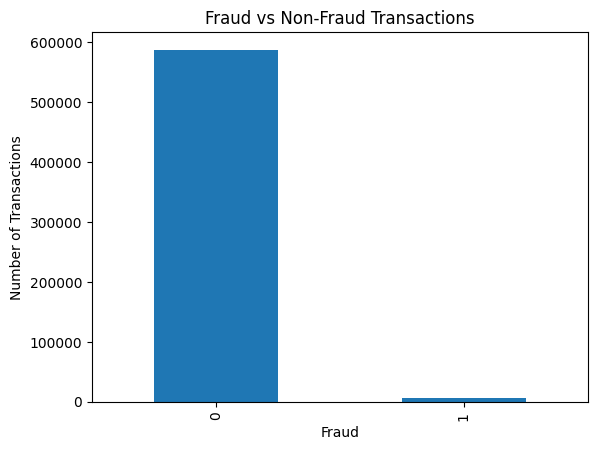

In [15]:
df['fraud'].value_counts().plot(kind='bar')
plt.title('Fraud vs Non-Fraud Transactions')
plt.xlabel('Fraud')
plt.ylabel('Number of Transactions')
plt.show()

**Exploratory Data Analysis (EDA)**

Exploratory data analysis is used to identify patterns in transaction behaviour and differences between fraudulent and legitimate payments. The analysis examines class distribution, transaction amounts and fraud rates across transaction categories to provide an initial understanding of the data.

In [16]:
# Transaction amount statistics by fraud status

df.groupby('fraud')['amount'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud,,,,,,,,
0,587443.0,31.847230,31.470876,0.00,13.59,26.610,41.8950,2144.86
1,7200.0,530.926551,835.587112,0.03,159.98,319.175,548.9775,8329.96


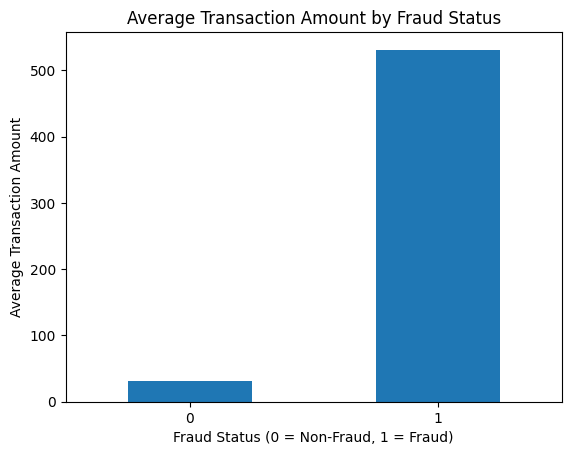

In [17]:
# Average transaction amount by fraud status

df.groupby('fraud')['amount'].mean().plot(kind='bar')

plt.title('Average Transaction Amount by Fraud Status')
plt.xlabel('Fraud Status (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('Average Transaction Amount')
plt.xticks(rotation=0)
plt.show()

In [18]:
# Fraud distribution as counts and percentages

fraud_counts = df['fraud'].value_counts()
fraud_percentages = df['fraud'].value_counts(normalize=True) * 100

fraud_summary = pd.DataFrame({
    'Count': fraud_counts,
    'Percentage': fraud_percentages
})

fraud_summary

,Count,Percentage
fraud,,
0,587443,98.789189
1,7200,1.210811


**Data Preprocessing**

The dataset is examined to identify variables that require cleaning or transformation before modelling. This includes reviewing categorical values, identifying variables with limited variation and checking how transaction characteristics should be represented for machine learning.

In [19]:
# Inspect categorical variables before preprocessing

for column in ['age', 'gender', 'zipcodeOri', 'zipMerchant']:
    print(f"\n{column}:")
    print(df[column].value_counts().sort_index())


age:
age
'0'      2452
'1'     58131
'2'    187310
'3'    147131
'4'    109025
'5'     62642
'6'     26774
'U'      1178
Name: count, dtype: int64

gender:
gender
'E'      1178
'F'    324565
'M'    268385
'U'       515
Name: count, dtype: int64

zipcodeOri:
zipcodeOri
'28007'    594643
Name: count, dtype: int64

zipMerchant:
zipMerchant
'28007'    594643
Name: count, dtype: int64


In [20]:
print("Unique customers:", df['customer'].nunique())
print("Unique merchants:", df['merchant'].nunique())
print("Unique categories:", df['category'].nunique())

Unique customers: 4112
Unique merchants: 50
Unique categories: 15


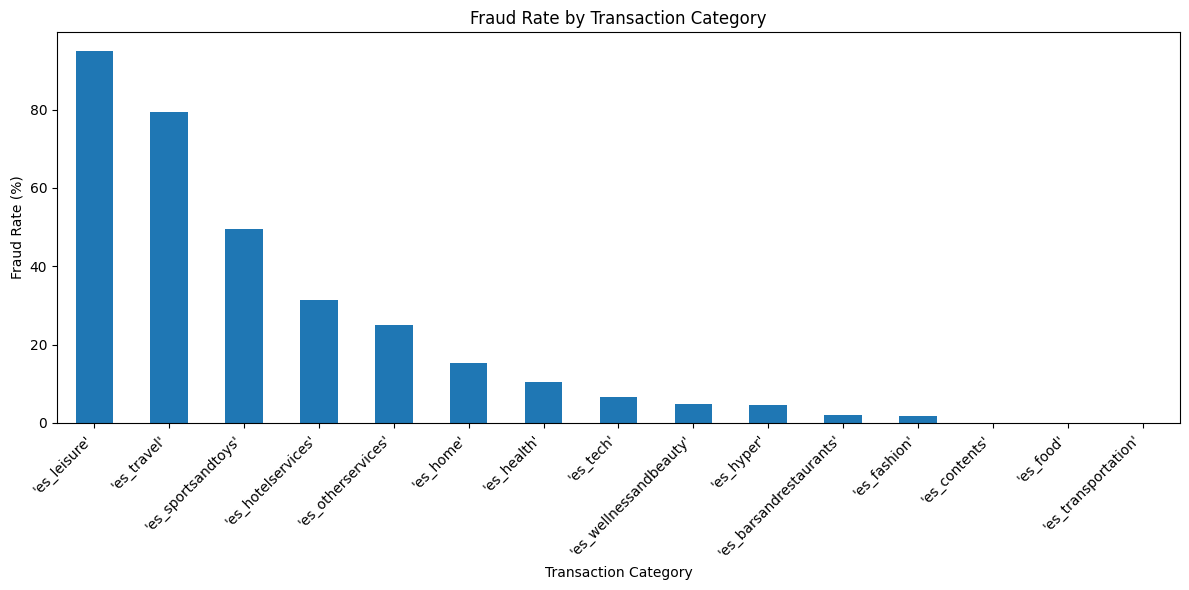

In [21]:
# Fraud rate by transaction category

category_fraud = (
    df.groupby('category')['fraud']
      .mean()
      .sort_values(ascending=False) * 100
)

category_fraud.plot(kind='bar', figsize=(12, 6))

plt.title('Fraud Rate by Transaction Category')
plt.xlabel('Transaction Category')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Prepare the data**

The fraud variable is separated from the remaining variables to define the prediction target and input features. This allows the models to learn relationships between transaction characteristics and whether a payment is fraudulent.

In [22]:
# Prepare features and target

X = df.drop('fraud', axis=1).copy()
y = df['fraud'].copy()

print("Feature dataset shape:", X.shape)
print("Target shape:", y.shape)

Feature dataset shape: (594643, 9)
Target shape: (594643,)


**Create training and testing data**

The dataset is divided into 70% training data and 30% testing data using stratified sampling to preserve the original fraud distribution. The preprocessing transformations are fitted on the training data and then applied to the test data to reduce the risk of information leakage.

In [23]:
# Split features and target

X = df.drop('fraud', axis=1).copy()
y = df['fraud'].copy()

# Create stratified 70:30 training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nFraud distribution in training set:")
print(y_train.value_counts(normalize=True) * 100)

print("\nFraud distribution in testing set:")
print(y_test.value_counts(normalize=True) * 100)

Training set: (416250, 9)
Testing set: (178393, 9)

Fraud distribution in training set:
fraud
0    98.789189
1     1.210811
Name: proportion, dtype: float64

Fraud distribution in testing set:
fraud
0    98.78919
1     1.21081
Name: proportion, dtype: float64


In [24]:
print("Age data type:", X_train['age'].dtype)
print("Unique age values:")
print(X_train['age'].unique())

print("\nFirst 10 age values:")
print(X_train['age'].head(10).tolist())

Age data type: object
Unique age values:
["'4'" "'3'" "'1'" "'6'" "'5'" "'2'" "'0'" "'U'"]

First 10 age values:
["'4'", "'3'", "'1'", "'3'", "'3'", "'4'", "'3'", "'3'", "'1'", "'6'"]


In [25]:
# Data preprocessing

from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer

# Create copies of the training and testing data
X_train_model = X_train.copy()
X_test_model = X_test.copy()

# Remove postcode variables because they contain only one value
X_train_model = X_train_model.drop(
    columns=['zipcodeOri', 'zipMerchant']
)

X_test_model = X_test_model.drop(
    columns=['zipcodeOri', 'zipMerchant']
)

# Clean quotation marks from categorical variables
categorical_columns = ['customer', 'age', 'gender', 'merchant', 'category']

for column in categorical_columns:
    X_train_model[column] = (
        X_train_model[column]
        .astype(str)
        .str.replace("'", "", regex=False)
    )

    X_test_model[column] = (
        X_test_model[column]
        .astype(str)
        .str.replace("'", "", regex=False)
    )

# Convert age to an ordinal numeric variable
# U represents unknown age and is retained as a separate value
age_mapping = {
    '0': 0,
    '1': 1,
    '2': 2,
    '3': 3,
    '4': 4,
    '5': 5,
    '6': 6,
    'U': -1
}

X_train_model['age'] = X_train_model['age'].map(age_mapping)
X_test_model['age'] = X_test_model['age'].map(age_mapping)

# Variables to transform
categorical_features = ['customer', 'gender', 'merchant', 'category']
numeric_features = ['amount']

# One-hot encode categorical variables and scale transaction amount
preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'amount',
            MinMaxScaler(),
            numeric_features
        )
    ],
    remainder='passthrough'
)

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train_model)

# Apply the same transformation to testing data
X_test_processed = preprocessor.transform(X_test_model)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nMissing age values after mapping:")
print("Training:", X_train_model['age'].isna().sum())
print("Testing:", X_test_model['age'].isna().sum())

Original training shape: (416250, 9)
Processed training shape: (416250, 4184)

Original testing shape: (178393, 9)
Processed testing shape: (178393, 4184)

Missing age values after mapping:
Training: 0
Testing: 0


**Exploratory Linear Regression Analysis**

Linear Regression is included as an exploratory comparison to examine how a regression approach behaves when predicting a binary fraud outcome. Its performance is assessed using RMSE, R² and a scatter plot. However, it is not treated as a primary fraud classifier because its continuous predictions do not directly represent valid binary classifications or necessarily remain between zero and one

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Exploratory Linear Regression model
linear_model = LinearRegression()

# Train using the preprocessed training data
linear_model.fit(X_train_processed, y_train)

# Generate predictions using the preprocessed testing data
linear_predictions = linear_model.predict(X_test_processed)

# Evaluate the regression model
mse = mean_squared_error(y_test, linear_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, linear_predictions)

print("Linear Regression RMSE:", round(rmse, 4))
print("Linear Regression R²:", round(r2, 4))

Linear Regression RMSE: 0.069
Linear Regression R²: 0.6023


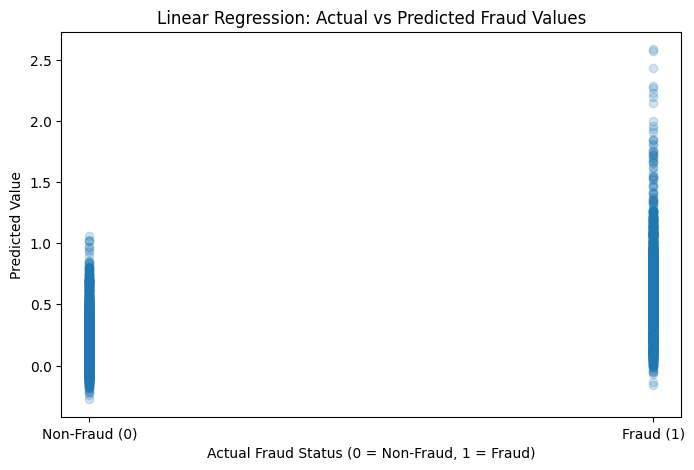

In [27]:
# Actual vs predicted values for exploratory Linear Regression

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.2
)

plt.xlabel('Actual Fraud Status (0 = Non-Fraud, 1 = Fraud)')
plt.ylabel('Predicted Value')
plt.title('Linear Regression: Actual vs Predicted Fraud Values')

plt.xticks([0, 1], ['Non-Fraud (0)', 'Fraud (1)'])

plt.show()

**Logistic Regression**

Logistic Regression is used as a baseline classification model to estimate the probability that a transaction is fraudulent. Its performance provides a reference point for evaluating whether more complex machine learning algorithms improve fraud detection.

In [ ]:
# Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model using preprocessed training data
log_model.fit(X_train_processed, y_train)

# Generate predictions
log_predictions = log_model.predict(X_test_processed)

# Predicted probabilities for later ROC-AUC analysis
log_prob = log_model.predict_proba(X_test_processed)[:, 1]

print(
    "Logistic Regression Accuracy:",
    accuracy_score(y_test, log_predictions)
)

print("\nClassification Report:")
print(classification_report(y_test, log_predictions))

**Random Forest**

Random Forest combines predictions from multiple decision trees to classify transactions as fraudulent or legitimate. It is included to examine whether an ensemble learning approach can capture complex patterns in transaction data and improve fraud detection performance


In [ ]:
# Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train using preprocessed training data
rf_model.fit(X_train_processed, y_train)

# Generate predictions
rf_predictions = rf_model.predict(X_test_processed)

# Predicted probabilities for later ROC-AUC analysis
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]

print(
    "Random Forest Accuracy:",
    accuracy_score(y_test, rf_predictions)
)

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

**Gradient Boosting**

Gradient Boosting builds decision trees sequentially, with each new tree attempting to correct errors made by the previous model. It is included as an additional classifier to compare the performance of different ensemble learning approaches.

In [ ]:
gb_model = GradientBoostingClassifier(
    random_state=42
)

# Train using preprocessed training data
gb_model.fit(X_train_processed, y_train)

# Generate predictions
gb_predictions = gb_model.predict(X_test_processed)

# Predicted probabilities for later ROC-AUC analysis
gb_prob = gb_model.predict_proba(X_test_processed)[:, 1]

print(
    "Gradient Boosting Accuracy:",
    accuracy_score(y_test, gb_predictions)
)

print("\nClassification Report:")
print(classification_report(y_test, gb_predictions))

**XGBoost**

XGBoost is a gradient-boosted tree algorithm designed to improve predictive performance through sequential model optimisation. It is evaluated alongside the other classifiers to determine how effectively it identifies fraudulent transactions in the imbalanced dataset.

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# Train using preprocessed training data
xgb_model.fit(X_train_processed, y_train)

# Generate predictions
xgb_predictions = xgb_model.predict(X_test_processed)

# Predicted probabilities for later ROC-AUC analysis
xgb_prob = xgb_model.predict_proba(X_test_processed)[:, 1]

print(
    "XGBoost Accuracy:",
    accuracy_score(y_test, xgb_predictions)
)

print("\nClassification Report:")
print(classification_report(y_test, xgb_predictions))

**Compare the models**

The four classification models are compared using accuracy, precision, recall, F1-score and ROC-AUC. Particular attention is given to recall and F1-score because fraudulent transactions represent a small proportion of the dataset, making overall accuracy potentially misleading.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create model comparison table
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Gradient Boosting',
        'XGBoost'
    ],

    'Accuracy': [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, gb_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],

    'Precision': [
        precision_score(y_test, log_predictions),
        precision_score(y_test, rf_predictions),
        precision_score(y_test, gb_predictions),
        precision_score(y_test, xgb_predictions)
    ],

    'Recall': [
        recall_score(y_test, log_predictions),
        recall_score(y_test, rf_predictions),
        recall_score(y_test, gb_predictions),
        recall_score(y_test, xgb_predictions)
    ],

    'F1-Score': [
        f1_score(y_test, log_predictions),
        f1_score(y_test, rf_predictions),
        f1_score(y_test, gb_predictions),
        f1_score(y_test, xgb_predictions)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, log_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, gb_prob),
        roc_auc_score(y_test, xgb_prob)
    ]
})

results.round(4)

**Model Evaluation – Confusion Matrices**

Confusion matrices are used to examine the number of correctly and incorrectly classified transactions for each model. They differentiate between detected fraud, missed fraud and legitimate transactions incorrectly flagged as fraudulent, providing a practical interpretation of model performance.

In [ ]:

# Confusion matrices for all classification models

models_predictions = {
    'Logistic Regression': log_predictions,
    'Random Forest': rf_predictions,
    'Gradient Boosting': gb_predictions,
    'XGBoost': xgb_predictions
}

for model_name, predictions in models_predictions.items():
    cm = confusion_matrix(y_test, predictions)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Non-Fraud', 'Fraud']
    )

    display.plot(values_format='d')
    plt.title(f'{model_name} Confusion Matrix')
    plt.show()

**Model Evaluation – ROC Curve**

ROC curves are used to compare how effectively the classification models differentiate fraudulent from legitimate transactions across different decision thresholds. The ROC-AUC score summarises this discrimination ability, although it must be considered alongside minority-class performance measures.

In [ ]:
# ROC Curve comparison for all classification models

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

model_probabilities = {
    'Logistic Regression': log_prob,
    'Random Forest': rf_prob,
    'Gradient Boosting': gb_prob,
    'XGBoost': xgb_prob
}

plt.figure(figsize=(8, 6))

for model_name, probabilities in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f'{model_name} (AUC = {auc_score:.4f})'
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

**Model Evaluation – Precision–Recall Curves**

Precision–recall curves examine the relationship between identifying fraudulent transactions and limiting false fraud alerts across different thresholds. This evaluation is particularly relevant because the BankSim dataset is highly imbalanced. Average Precision provides an additional summary of each model's performance on the fraud class

In [ ]:

# Precision–Recall Curve comparison for all classification models

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Use the predicted fraud probabilities from the trained models
model_probabilities = {
    'Logistic Regression': log_prob,
    'Random Forest': rf_prob,
    'Gradient Boosting': gb_prob,
    'XGBoost': xgb_prob
}

plt.figure(figsize=(9, 6))

# Calculate precision, recall and average precision for each model
for model_name, probabilities in model_probabilities.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test, probabilities
    )

    ap_score = average_precision_score(
        y_test, probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f'{model_name} (AP = {ap_score:.4f})'
    )

# Baseline represents the proportion of fraud cases in the test set
baseline = y_test.mean()

plt.axhline(
    y=baseline,
    color='gray',
    linestyle='--',
    label=f'Fraud Prevalence = {baseline:.4f}'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curve Comparison')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Compare Average Precision scores

ap_results = pd.DataFrame({
    'Model': list(model_probabilities.keys()),
    'Average Precision': [
        average_precision_score(y_test, probabilities)
        for probabilities in model_probabilities.values()
    ]
})

ap_results = ap_results.sort_values(
    by='Average Precision',
    ascending=False
)

print(ap_results.round(4).to_string(index=False))


**Five-Fold Stratified Cross-Validation**

Five-fold stratified cross-validation is used to assess the stability of model performance across different training and validation subsets. Stratification preserves the proportion of fraudulent and legitimate transactions in each fold. Preprocessing is fitted separately within each training fold to reduce information leakage, while the original test set remains excluded from cross-validation.

In [ ]:

# Five-fold stratified cross-validation setup

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Work with the original training set only
X_cv = X_train_model.copy()
y_cv = y_train.copy()

# Define preprocessing for each training fold
cv_preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            ['customer', 'gender', 'merchant', 'category']
        ),
        (
            'amount',
            MinMaxScaler(),
            ['amount']
        )
    ],
    remainder='passthrough'
)

# Define five stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Check fraud distribution in each fold
for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_cv, y_cv), start=1
):
    y_fold_train = y_cv.iloc[train_idx]
    y_fold_val = y_cv.iloc[val_idx]

    print(f"Fold {fold}")
    print(f"  Training rows: {len(train_idx):,}")
    print(f"  Validation rows: {len(val_idx):,}")
    print(f"  Training fraud rate: {y_fold_train.mean():.4%}")
    print(f"  Validation fraud rate: {y_fold_val.mean():.4%}")


**Logistic Regression cross-validation**

Logistic Regression is evaluated using five-fold stratified cross-validation to assess the consistency of its fraud detection performance across different subsets of the training data. Preprocessing is performed within each fold, and the results are summarised using recall, F1-score and Average Precision. This provides a more reliable assessment of model stability than relying on a single training and testing split.

In [ ]:

# Logistic Regression - Five-fold stratified cross-validation

from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import pandas as pd

# Create a pipeline to avoid preprocessing leakage
lr_cv_pipeline = Pipeline([
    ('preprocessing', cv_preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Evaluate using three fraud-focused metrics
lr_cv_scores = cross_validate(
    lr_cv_pipeline,
    X_cv,
    y_cv,
    cv=cv,
    scoring={
        'Recall': 'recall',
        'F1-Score': 'f1',
        'Average Precision': 'average_precision'
    },
    n_jobs=1,
    error_score='raise'
)

# Summarise the results across five folds
lr_cv_results = pd.DataFrame({
    'Metric': [
        'Recall',
        'F1-Score',
        'Average Precision'
    ],
    'Mean': [
        lr_cv_scores['test_Recall'].mean(),
        lr_cv_scores['test_F1-Score'].mean(),
        lr_cv_scores['test_Average Precision'].mean()
    ],
    'Standard Deviation': [
        lr_cv_scores['test_Recall'].std(),
        lr_cv_scores['test_F1-Score'].std(),
        lr_cv_scores['test_Average Precision'].std()
    ]
})

print(lr_cv_results.round(4).to_string(index=False))


**Random Forest – Cross-Validation**

Random Forest is evaluated using five-fold stratified cross-validation to assess whether its performance remains consistent across different training subsets. Recall, F1-score and Average Precision are examined to determine how reliably the ensemble model identifies fraudulent transactions and whether its performance advantage over Logistic Regression is maintained.

In [ ]:

# Random Forest - Five-fold stratified cross-validation

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
import pandas as pd
import numpy as np

# Create Random Forest pipeline
rf_cv_pipeline = Pipeline([
    ('preprocessing', cv_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Evaluate model using five stratified folds
rf_cv_scores = cross_validate(
    rf_cv_pipeline,
    X_cv,
    y_cv,
    cv=cv,
    scoring={
        'Recall': 'recall',
        'F1-Score': 'f1',
        'Average Precision': 'average_precision'
    },
    n_jobs=1,
    error_score='raise'
)

# Summarise cross-validation performance
rf_cv_results = pd.DataFrame({
    'Metric': [
        'Recall',
        'F1-Score',
        'Average Precision'
    ],
    'Mean': [
        rf_cv_scores['test_Recall'].mean(),
        rf_cv_scores['test_F1-Score'].mean(),
        rf_cv_scores['test_Average Precision'].mean()
    ],
    'Standard Deviation': [
        rf_cv_scores['test_Recall'].std(),
        rf_cv_scores['test_F1-Score'].std(),
        rf_cv_scores['test_Average Precision'].std()
    ]
})

print(rf_cv_results.round(4).to_string(index=False))


**XGBoost cross-validation**

XGBoost is evaluated using five-fold stratified cross-validation to assess the consistency of its fraud detection performance across different training subsets. Recall, F1-score and Average Precision are used to compare its effectiveness against Logistic Regression and Random Forest.

In [ ]:

# XGBoost - Five-fold stratified cross-validation

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
import pandas as pd

xgb_cv_pipeline = Pipeline([
    ('preprocessing', cv_preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=100,
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ))
])

xgb_cv_scores = cross_validate(
    xgb_cv_pipeline,
    X_cv,
    y_cv,
    cv=cv,
    scoring={
        'Recall': 'recall',
        'F1-Score': 'f1',
        'Average Precision': 'average_precision'
    },
    n_jobs=1,
    error_score='raise'
)

xgb_cv_results = pd.DataFrame({
    'Metric': [
        'Recall',
        'F1-Score',
        'Average Precision'
    ],
    'Mean': [
        xgb_cv_scores['test_Recall'].mean(),
        xgb_cv_scores['test_F1-Score'].mean(),
        xgb_cv_scores['test_Average Precision'].mean()
    ],
    'Standard Deviation': [
        xgb_cv_scores['test_Recall'].std(),
        xgb_cv_scores['test_F1-Score'].std(),
        xgb_cv_scores['test_Average Precision'].std()
    ]
})

print(xgb_cv_results.round(4).to_string(index=False))


**Cross-Validation Results Comparison**

The cross-validation results are compared to evaluate the consistency and predictive performance of the three primary classification algorithms. Mean recall, F1-score and Average Precision are used to assess fraud detection effectiveness, while standard deviations indicate how much model performance varies across the five folds.

In [ ]:

# Consolidated five-fold cross-validation results

cv_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],
    'Mean Recall': [
        lr_cv_scores['test_Recall'].mean(),
        rf_cv_scores['test_Recall'].mean(),
        xgb_cv_scores['test_Recall'].mean()
    ],
    'Recall SD': [
        lr_cv_scores['test_Recall'].std(),
        rf_cv_scores['test_Recall'].std(),
        xgb_cv_scores['test_Recall'].std()
    ],
    'Mean F1': [
        lr_cv_scores['test_F1-Score'].mean(),
        rf_cv_scores['test_F1-Score'].mean(),
        xgb_cv_scores['test_F1-Score'].mean()
    ],
    'F1 SD': [
        lr_cv_scores['test_F1-Score'].std(),
        rf_cv_scores['test_F1-Score'].std(),
        xgb_cv_scores['test_F1-Score'].std()
    ],
    'Mean AP': [
        lr_cv_scores['test_Average Precision'].mean(),
        rf_cv_scores['test_Average Precision'].mean(),
        xgb_cv_scores['test_Average Precision'].mean()
    ],
    'AP SD': [
        lr_cv_scores['test_Average Precision'].std(),
        rf_cv_scores['test_Average Precision'].std(),
        xgb_cv_scores['test_Average Precision'].std()
    ]
})

print(cv_comparison.round(4).to_string(index=False))


**Random Forest hyperparameter tuning**


GridSearchCV was used to test whether adjusting the Random Forest parameters could improve fraud detection performance.

Four combinations of `max_depth` and `min_samples_leaf` were evaluated using three-fold stratified cross-validation. The number of trees was fixed at 100, and Average Precision was used to select the best combination.

The tuning was performed on the training data, with preprocessing fitted separately within each fold. The test data was kept aside for the final evaluation.


In [ ]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
import time

# Reuse the fold-wise preprocessing pipeline
rf_tuning_pipeline = Pipeline([
    ('preprocessor', cv_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ))
])

# Small grid to limit computational cost
param_grid = {
    'classifier__max_depth': [None, 20],
    'classifier__min_samples_leaf': [1, 3]
}

tuning_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

rf_grid = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=param_grid,
    scoring='average_precision',
    cv=tuning_cv,
    n_jobs=1,
    verbose=2,
    refit=True
)

start = time.time()

rf_grid.fit(X_cv, y_cv)

print("\nBest parameters:", rf_grid.best_params_)
print("Best CV Average Precision:",
      round(rf_grid.best_score_, 4))
print("Time taken:",
      round((time.time() - start) / 60, 2),
      "minutes")


**Analysis Summary**

Exploratory data analysis was conducted to study the structure and quality of the dataset, the distribution of classes and transaction amounts, and fraud patterns across different transaction categories. The data was then pre-processed and divided into a 70% training set and a 30% testing set using stratified sampling to preserve the original class distribution. Linear Regression was included as an exploratory regression-based analysis, while Logistic Regression, Random Forest, Gradient Boosting and XGBoost were applied to the fraud classification problem. The classification models were evaluated using accuracy, precision, recall, F1-score and ROC-AUC, supported by confusion matrices and ROC curves.

The Random Forest model stood out as the best perfoming model. In the precision–recall analysis, it reached the highest average precision at 0.9136. When tested with five‑fold cross‑validation, it maintained strong mean scores: recall at 0.7921, F1 at 0.8412, and AP at 0.9181. What makes these results especially convincing is that Random Forest showed the least variation across folds compared to the other models, highlighting its stability. One limitation worth noting is that SMOTE was not applied, its potential effect remains untested in addressing the class imbalance.